<a href="https://colab.research.google.com/github/junaidatta123/Scientific-Projects/blob/main/Imagefiltering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [41]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from helper_functions import *

In [43]:
file_name = "part.png"
A_color = Image.open(file_name)
A_g = A_color.convert('L')
A = np.array(A_g)
print("type", type(A), "shape", A.shape)

type <class 'numpy.ndarray'> shape (12, 12)


In [44]:
print(A[1, 2])

250


In [45]:
print(A)

[[  0   0 113 104   0   0   0  59 151 141   0   0]
 [  0 150 250 216   0   0 108 238 249 246 220   0]
 [ 48 246 249 214   0   0 215 246 147 188 246 141]
 [ 92 187 245 214   0   0 151 152   0 123 249 166]
 [  0   0 246 211   0   0   0   0   0 172 250 131]
 [  0   0 246 202   0   0   0   0  73 242 217   0]
 [  0   0 243 205   0   0   0   0 207 247  97   0]
 [  0   0 247 200   0   0   0 145 251 166   0   0]
 [  0   0 250 208   0   0  54 237 226   0   0   0]
 [  0   0 251 215   0   0 202 250 194 168 168 102]
 [  0   0 249 216   0   0 225 249 249 250 249 166]
 [  0   0 108  95   0   0  99 112 117 120 113  79]]


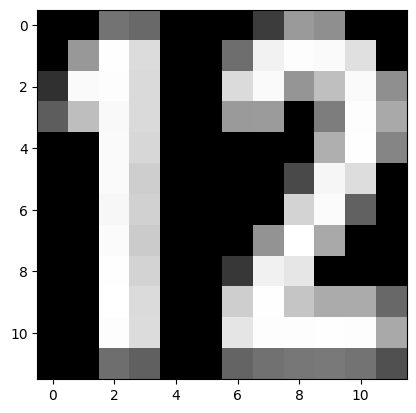

In [46]:
plt.imshow(A, "grey")

In [47]:
def local_convolution(A, K, i, j):
    v = 0
    for m in range(3):      # kernel rows
        for n in range(3):  # kernel columns
            v += A[i - 1 + m, j - 1 + n] * K[m, n]
    return v

In [48]:
# Image Convolution
def im_filtering(A, K):
    rows, cols = A.shape
    # Create an output matrix for the result
    R = np.zeros(shape=(rows - 2, cols - 2))

    for i in range(1, rows - 1):      # internal rows
        for j in range(1, cols - 1):  # internal columns
            R[i - 1, j - 1] = local_convolution(A, K, i, j)

    return R

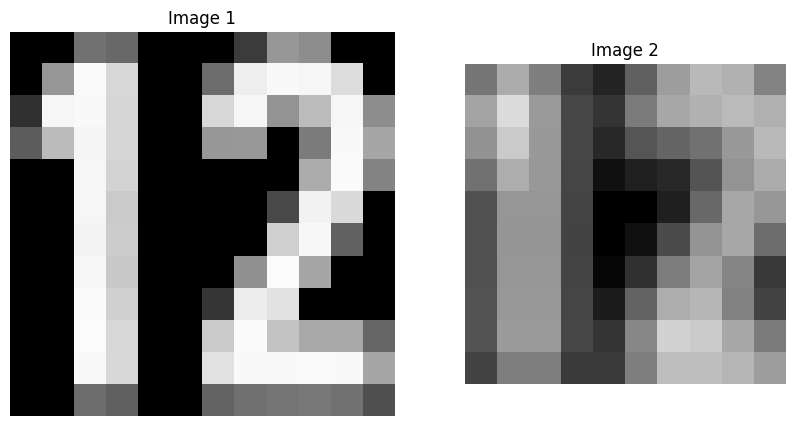

In [49]:
# Blurring kernel
K = np.ones([3, 3]) / 9
R = im_filtering(A, K)
compare_images(A, R)

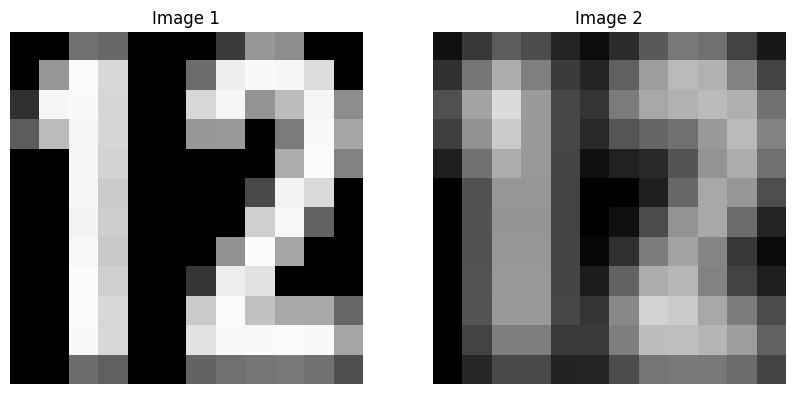

In [51]:
# Padding
Ap = np.zeros((A.shape[0] + 2, A.shape[1] + 2))
Ap[1:-1, 1:-1] = A

Rp = im_filtering(Ap, K)
compare_images(A, Rp)